# 03: Modeling

Trains, tunes and compares five models from the course, plus two no-learning baselines:

| # | Model | Course source | Role |
|---|---|---|---|
| 0a | Median price | none | "No model" baseline |
| 0b | ZIP $/sqft × house size | none | Real-estate rule of thumb |
| 1 | Linear regression, **OLS** (normal equation) | Derivatives & OLS HW | Interpretable baseline |
| 2 | Linear regression, **gradient descent (LMS)** | GD & LMS HW | Same model, iterative training |
| 3 | **Polynomial features + Ridge** | Curve Fitting & Regularization HW | Curves + interactions, controlled overfitting |
| 4 | **KNN regression** | Linear Algebra & KNN HW | "Comparable homes" |
| 5 | **Neural network** (MLP) | Neural Networks lectures, ML sketch | Flexible nonlinear model |

**Protocol:** fit on **train**, choose settings on **validation**, and evaluate the chosen models **once** on **test** at the end.

**How to read the metrics.** Models predict log(price); we convert back to dollars.
- **Median % error**: half of homes are predicted closer than this. Example: a $300k home predicted at $345k is a 15% error.
- **Within 20%**: share of homes predicted within ±20% of their true price.
- **MAE ($)**: average dollar miss. **RMSE ($)** is similar but punishes big misses more, so a few mansions inflate it.
- **R²**: share of price variation explained (1 = perfect, 0 = no better than guessing the average).

In [1]:
import sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import PolynomialFeatures

sys.path.insert(0, str(Path.cwd().parent / "src"))
import preprocess as pp
from models import (OrdinaryLeastSquares, RidgeOrdinaryLeastSquares, LeastMeanSquares,
                    KNearestNeighborsRegressor, evaluate, rmse)
from plot_style import apply_style, save, BLUE, ORANGE, TEXT_2, SEQ_BLUE

apply_style()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
SEED = 42

data = pp.load_processed()
X_trn, y_trn, X_val, y_val, X_tst, y_tst, scaler = pp.get_arrays(data)
FEATURES = pp.FEATURES
print("train", X_trn.shape, "| val", X_val.shape, "| test", X_tst.shape)

val_results = {}   # model name -> validation metrics of its best setting

def show(metrics_by_name):
    df = pd.DataFrame(metrics_by_name).T
    return df.style.format({"RMSE (log)": "{:.3f}", "R² (log)": "{:.3f}", "MAE ($)": "${:,.0f}",
                            "RMSE ($)": "${:,.0f}", "R² ($)": "{:.3f}", "Median % error": "{:.1f}%",
                            "Within 10%": "{:.1f}%", "Within 20%": "{:.1f}%"})

train (28273, 7) | val (6058, 7) | test (6059, 7)


## 0. Baselines (no learning)

In [2]:
# 0a: predict the training median price for every home
median_log = np.median(y_trn)
val_results["0a. Median price"] = evaluate(y_val, np.full_like(y_val, median_log))

# 0b: price = ZIP median $/sqft x house size, how an agent would ballpark it
v = data["val"]
val_results["0b. ZIP $/sqft × size"] = evaluate(y_val, (v.zip_log_ppsf + np.log(v.house_size)).values)
show(val_results)

,RMSE (log),R² (log),MAE ($),RMSE ($),R² ($),Median % error,Within 10%,Within 20%
0a. Median price,0.633,-0.000,"$195,632","$376,041",-0.050,34.0%,15.8%,30.7%
0b. ZIP $/sqft × size,0.318,0.747,"$98,200","$220,387",0.639,15.7%,34.8%,60.1%


## 1. Linear regression with OLS

The model is log(price) = w₀ + w₁·x₁ + … + w₇·x₇. OLS finds the weights in one step with the **normal equation** w = (XᵀX)⁻¹Xᵀy, using `pinv` as in the homework.
It's checked against scikit-learn below; the weights should match to rounding error.

In [3]:
ols = OrdinaryLeastSquares().fit(X_trn, y_trn)
sk = LinearRegression().fit(X_trn, y_trn)
print(f"Largest difference from scikit-learn's weights: {np.abs(ols.w[1:] - sk.coef_).max():.1e}")
val_results["1. Linear regression (OLS)"] = evaluate(y_val, ols.predict(X_val))
print(f"Train RMSE (log) {rmse(y_trn, ols.predict(X_trn)):.3f} vs. validation {val_results['1. Linear regression (OLS)']['RMSE (log)']:.3f}  (close = not overfitting)")
show({k: val_results[k] for k in ["1. Linear regression (OLS)"]})

Largest difference from scikit-learn's weights: 7.8e-15
Train RMSE (log) 0.307 vs. validation 0.305  (close = not overfitting)


,RMSE (log),R² (log),MAE ($),RMSE ($),R² ($),Median % error,Within 10%,Within 20%
1. Linear regression (OLS),0.305,0.768,"$95,106","$204,934",0.688,15.5%,33.6%,61.8%


### What the coefficients mean

Two views:
- **Standardized weights** (the model above): every feature is on the same scale, so bigger |weight| means more influence. Use this to rank features.
- **Unstandardized weights** (refit on the original units): these give real-world meanings. The target is log(price), so a weight *b* on a count feature means "+1 unit → price × e^b". On `log_house_size` it means "1% bigger home → about *b*% higher price".

Every effect is "**holding the other features fixed**". An extra bedroom *with the same square footage* means smaller rooms, so its effect can be small or even negative.

,standardized weight,original-units weight,meaning
log_house_size,0.350,0.795,1% bigger home -> 0.80% higher price
zip_log_ppsf,0.307,1.061,1% pricier ZIP ($/sqft) -> 1.06% higher price
bath,0.101,0.095,+1 bathroom (same sqft) -> +9.9%
log_acre_lot,0.068,0.140,+1 unit of log(1+acres) -> +15.1%
sold,-0.039,-0.079,sold (vs. still for sale) -> -7.6%
bed,-0.017,-0.018,+1 bedroom (same sqft) -> -1.8%
acre_lot_missing,-0.014,-0.040,lot size not listed -> -3.9%


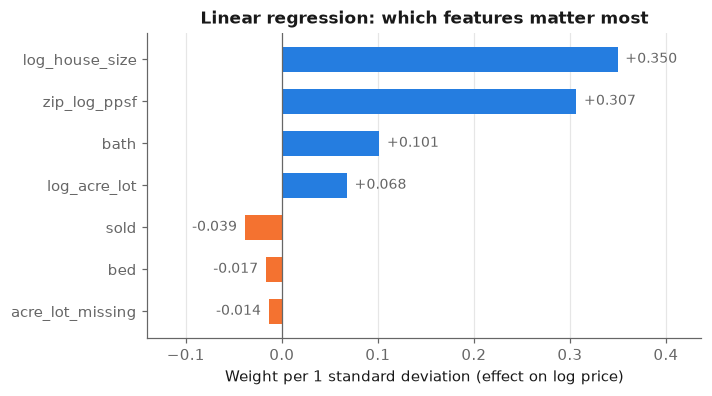

In [4]:
Xr = data["train"][FEATURES].to_numpy(float)
ols_raw = OrdinaryLeastSquares().fit(Xr, y_trn)
meaning = {
    "log_house_size": lambda b: f"1% bigger home -> {b:.2f}% higher price",
    "bed": lambda b: f"+1 bedroom (same sqft) -> {np.expm1(b)*100:+.1f}%",
    "bath": lambda b: f"+1 bathroom (same sqft) -> {np.expm1(b)*100:+.1f}%",
    "log_acre_lot": lambda b: f"+1 unit of log(1+acres) -> {np.expm1(b)*100:+.1f}%",
    "acre_lot_missing": lambda b: f"lot size not listed -> {np.expm1(b)*100:+.1f}%",
    "sold": lambda b: f"sold (vs. still for sale) -> {np.expm1(b)*100:+.1f}%",
    "zip_log_ppsf": lambda b: f"1% pricier ZIP ($/sqft) -> {b:.2f}% higher price",
}
coef = pd.DataFrame({"standardized weight": ols.w[1:], "original-units weight": ols_raw.w[1:]}, index=FEATURES)
coef["meaning"] = [meaning[f](b) for f, b in zip(FEATURES, ols_raw.w[1:])]
coef = coef.reindex(coef["standardized weight"].abs().sort_values(ascending=False).index)
display(coef)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
c = coef["standardized weight"][::-1]
ax.barh(c.index, c.values, color=[BLUE if v >= 0 else ORANGE for v in c.values], height=0.6)
ax.axvline(0, color=TEXT_2, linewidth=0.8)
for y, v in enumerate(c.values):
    ax.text(v + (0.008 if v >= 0 else -0.008), y, f"{v:+.3f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color=TEXT_2)
ax.set_xlabel("Weight per 1 standard deviation (effect on log price)")
ax.set_title("Linear regression: which features matter most")
ax.set_xlim(-0.14, c.max() * 1.25)
ax.grid(axis="y", visible=False)
save(fig, "fig11_ols_coefficients")
plt.show()

## 2. Linear regression with gradient descent (LMS)

The same model trained a different way. Start from random weights and repeatedly step **downhill** on the error:

w ← w − α · ∇MSE, where ∇MSE = (2/m)·Xᵀ(Xw − y)

using mini-batches of 64 homes. The learning rate **α** sets the step size: too small and it crawls, too large and it overshoots.
If gradient descent works, it should land on the same answer OLS computed directly.

alpha=0.0003  final val RMSE (log) 0.3047 | max |w - w_OLS| = 0.0211 | 0.5s


alpha=0.003   final val RMSE (log) 0.3045 | max |w - w_OLS| = 0.0029 | 0.4s


alpha=0.03    final val RMSE (log) 0.3047 | max |w - w_OLS| = 0.0147 | 0.5s


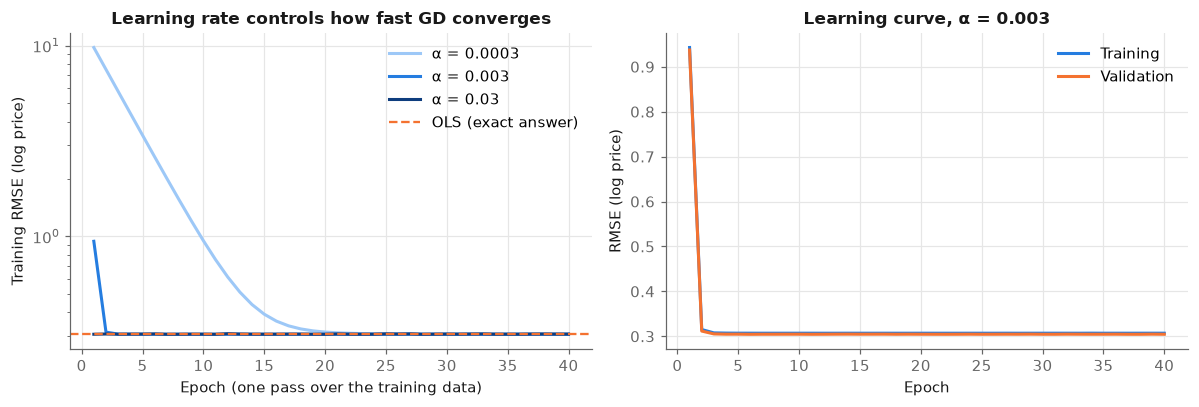

In [5]:
curves = {}
for alpha in [0.0003, 0.003, 0.03]:
    t = time.time()
    m = LeastMeanSquares(alpha=alpha, batch_size=64, epochs=40, seed=SEED).fit(X_trn, y_trn, X_val, y_val)
    curves[alpha] = m
    print(f"alpha={alpha:<7} final val RMSE (log) {m.val_error[-1]:.4f} | max |w - w_OLS| = "
          f"{np.abs(m.w - ols.w).max():.4f} | {time.time() - t:.1f}s")

best_alpha = min(curves, key=lambda a: curves[a].val_error[-1])
lms = curves[best_alpha]
val_results["2. Linear regression (gradient descent)"] = evaluate(y_val, lms.predict(X_val))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for alpha, color, ls in zip(curves, ["#9dc8f7", BLUE, "#0e3d7e"], ["-", "-", "-"]):
    axes[0].plot(range(1, 41), curves[alpha].trn_error, color=color, linewidth=2, label=f"α = {alpha}")
axes[0].axhline(rmse(y_trn, ols.predict(X_trn)), color=ORANGE, linestyle="--", linewidth=1.5, label="OLS (exact answer)")
axes[0].set_yscale("log")
axes[0].set_xlabel("Epoch (one pass over the training data)")
axes[0].set_ylabel("Training RMSE (log price)")
axes[0].set_title("Learning rate controls how fast GD converges")
axes[0].legend()
axes[1].plot(range(1, 41), lms.trn_error, color=BLUE, linewidth=2, label="Training")
axes[1].plot(range(1, 41), lms.val_error, color=ORANGE, linewidth=2, label="Validation")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("RMSE (log price)")
axes[1].set_title(f"Learning curve, α = {best_alpha}")
axes[1].legend()
fig.tight_layout()
save(fig, "fig12_gradient_descent")
plt.show()

## 3. Polynomial features + Ridge regression

A straight line can't bend. **Polynomial features** add squared terms and pairwise products: degree 2 adds size², size×ZIP, bath×bed, and so on. That lets the model learn curves (each extra square foot is worth less in a huge home) and interactions (an extra square foot is worth more in a pricey ZIP).

More features means more risk of **overfitting**: memorizing training noise. **Ridge** adds a penalty λ·‖w‖² that keeps the weights small:
w = (XᵀX + λI)⁻¹Xᵀy (Ridge OLS from the regularization homework; the bias term isn't penalized).

We try degrees 1, 2 and 3 with λ from 0.001 to 10,000 and pick the pair with the lowest **validation** error.

Best setting: {'degree': 3.0, 'features': 119.0, 'lambda': 100.0, 'train RMSE': 0.29815330148338676, 'val RMSE': 0.2959965265916231}


,degree,features,lambda,train RMSE,val RMSE
11,1,7,316.228,0.307,0.305
25,2,35,100.000,0.302,0.299
40,3,119,100.000,0.298,0.296


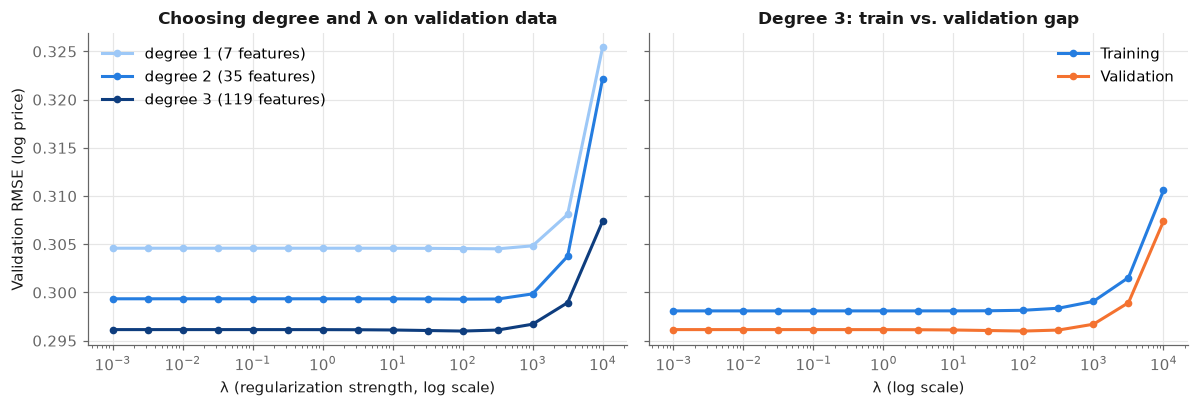

In [6]:
def poly_data(degree):
    pf = PolynomialFeatures(degree, include_bias=False)
    P_trn, P_val, P_tst = pf.fit_transform(X_trn), pf.transform(X_val), pf.transform(X_tst)
    st = pp.Standardize().fit(P_trn)
    sd = np.where(st.std == 0, 1, st.std)  # binary^2 duplicates can be constant-free but guard anyway
    f = lambda P: (P - st.mean) / sd
    return f(P_trn), f(P_val), f(P_tst), pf

lambdas = np.logspace(-3, 4, 15)
ridge_grid, poly_cache = [], {}
for degree in [1, 2, 3]:
    P_trn, P_val, P_tst, pf = poly_data(degree)
    poly_cache[degree] = (P_trn, P_val, P_tst)
    for lamb in lambdas:
        m = RidgeOrdinaryLeastSquares(lamb).fit(P_trn, y_trn)
        ridge_grid.append({"degree": degree, "features": P_trn.shape[1], "lambda": lamb,
                           "train RMSE": rmse(y_trn, m.predict(P_trn)), "val RMSE": rmse(y_val, m.predict(P_val))})
ridge_grid = pd.DataFrame(ridge_grid)
best_ridge = ridge_grid.loc[ridge_grid["val RMSE"].idxmin()]
print("Best setting:", best_ridge.to_dict())
display(ridge_grid.loc[ridge_grid.groupby("degree")["val RMSE"].idxmin()])

ridge_deg, ridge_lamb = int(best_ridge.degree), float(best_ridge["lambda"])
P_trn, P_val, P_tst = poly_cache[ridge_deg]
ridge = RidgeOrdinaryLeastSquares(ridge_lamb).fit(P_trn, y_trn)
val_results["3. Polynomial + Ridge"] = evaluate(y_val, ridge.predict(P_val))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
shades = {1: "#9dc8f7", 2: BLUE, 3: "#0e3d7e"}
for degree in [1, 2, 3]:
    g = ridge_grid[ridge_grid.degree == degree]
    n = int(g.features.iloc[0])
    axes[0].plot(g["lambda"], g["val RMSE"], color=shades[degree], linewidth=2, marker="o", markersize=4,
                 label=f"degree {degree} ({n} features)")
axes[0].set_xscale("log")
axes[0].set_xlabel("λ (regularization strength, log scale)")
axes[0].set_ylabel("Validation RMSE (log price)")
axes[0].set_title("Choosing degree and λ on validation data")
axes[0].legend()
g = ridge_grid[ridge_grid.degree == 3]
axes[1].plot(g["lambda"], g["train RMSE"], color=BLUE, linewidth=2, marker="o", markersize=4, label="Training")
axes[1].plot(g["lambda"], g["val RMSE"], color=ORANGE, linewidth=2, marker="o", markersize=4, label="Validation")
axes[1].set_xscale("log")
axes[1].set_xlabel("λ (log scale)")
axes[1].set_title("Degree 3: train vs. validation gap")
axes[1].legend()
fig.tight_layout()
save(fig, "fig13_ridge_tuning")
plt.show()

## 4. KNN regression

To price a home, find the **k most similar training homes** (smallest Euclidean distance across the 7 standardized features) and average their log prices. That's essentially what an appraiser's "comps" are.
This is the homework's `KNearestNeighbors` with one change: **average instead of majority vote**, since price is a number, not a class.

- **Small k** (e.g. 1) copies one neighbor, noise included, so it overfits: training error near 0, validation error high.
- **Large k** averages so many homes that local differences wash out, so it underfits.

Training error is measured on 5,000 training homes, *excluding each home itself* from its own neighbors; otherwise k = 1 would trivially score a perfect 0.

Neighbor search: 5.5s


,k,train RMSE (leave-self-out),val RMSE
0,1,0.402,0.383
1,2,0.348,0.339
2,3,0.329,0.322
3,5,0.313,0.308
4,7,0.308,0.304
5,10,0.304,0.300
6,15,0.303,0.298
7,20,0.303,0.299
8,30,0.303,0.300
9,50,0.306,0.303


Best k = 15. scikit-learn val RMSE 0.2980 vs ours 0.2980 (tiny differences come from ties: many homes share identical feature values)


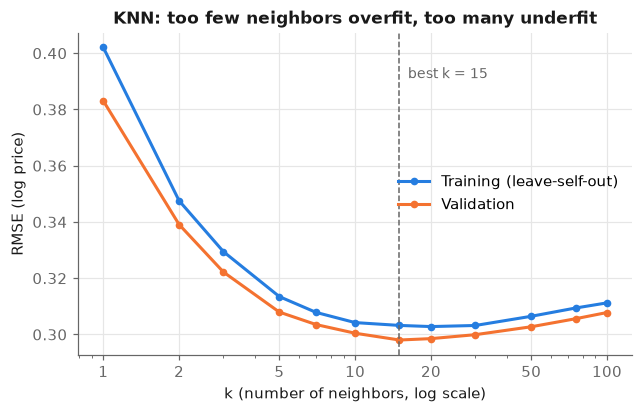

In [7]:
ks = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100]
knn = KNearestNeighborsRegressor(k=10).fit(X_trn, y_trn)
t = time.time()
val_preds = knn.predict_many_k(X_val, ks)
sample = np.random.RandomState(SEED).choice(len(X_trn), 5000, replace=False)
trn_preds = knn.predict_many_k(X_trn[sample], ks, skip_self=True)
print(f"Neighbor search: {time.time() - t:.1f}s")

knn_grid = pd.DataFrame({"k": ks,
                         "train RMSE (leave-self-out)": [rmse(y_trn[sample], trn_preds[k]) for k in ks],
                         "val RMSE": [rmse(y_val, val_preds[k]) for k in ks]})
display(knn_grid)
best_k = int(knn_grid.loc[knn_grid["val RMSE"].idxmin(), "k"])
knn.k = best_k
val_results["4. KNN regression"] = evaluate(y_val, val_preds[best_k])

sk_pred = KNeighborsRegressor(best_k).fit(X_trn, y_trn).predict(X_val)
print(f"Best k = {best_k}. scikit-learn val RMSE {rmse(y_val, sk_pred):.4f} vs ours {rmse(y_val, val_preds[best_k]):.4f} "
      f"(tiny differences come from ties: many homes share identical feature values)")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(knn_grid.k, knn_grid["train RMSE (leave-self-out)"], color=BLUE, linewidth=2, marker="o", markersize=4, label="Training (leave-self-out)")
ax.plot(knn_grid.k, knn_grid["val RMSE"], color=ORANGE, linewidth=2, marker="o", markersize=4, label="Validation")
ax.axvline(best_k, color=TEXT_2, linestyle="--", linewidth=1)
ax.text(best_k * 1.08, ax.get_ylim()[1] * 0.97, f"best k = {best_k}", color=TEXT_2, fontsize=9, va="top")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.ScalarFormatter())
ax.set_xticks([1, 2, 5, 10, 20, 50, 100])
ax.set_xlabel("k (number of neighbors, log scale)")
ax.set_ylabel("RMSE (log price)")
ax.set_title("KNN: too few neighbors overfit, too many underfit")
ax.legend()
save(fig, "fig14_knn_tuning")
plt.show()

## 5. Neural network (multilayer perceptron)

A neural network stacks layers of units. Each unit computes a weighted sum of its inputs and passes it through **ReLU** (max(0, z)), so the network can bend and combine features in ways a linear model can't.
It's trained with **backpropagation** + the Adam optimizer (a gradient-descent variant) on squared error. Settings tried:
- **Architecture**: 1 layer of 32 units; 2 layers (64, 32); 3 layers (128, 64, 32).
- **alpha**: an L2 penalty on the weights, the same idea as Ridge's λ.

`early_stopping=True` holds out 10% of the training data and stops when that score stops improving, which guards against overfitting.

,layers,alpha,epochs,train RMSE,val RMSE,seconds
0,"(32,)",0.000,107,0.298,0.298,5.600
1,"(32,)",0.010,107,0.298,0.298,5.500
2,"(32,)",1.000,86,0.303,0.301,4.900
3,"(64, 32)",0.000,100,0.292,0.294,10.400
4,"(64, 32)",0.010,100,0.292,0.294,10.300
5,"(64, 32)",1.000,77,0.300,0.299,7.700
6,"(128, 64, 32)",0.000,61,0.295,0.298,18.200
7,"(128, 64, 32)",0.010,61,0.295,0.298,19.700
8,"(128, 64, 32)",1.000,53,0.298,0.296,16.300


Best: {'layers': '(64, 32)', 'alpha': 0.01, 'epochs': 100, 'train RMSE': 0.2921307174617727, 'val RMSE': 0.29365714982433094, 'seconds': 10.3}


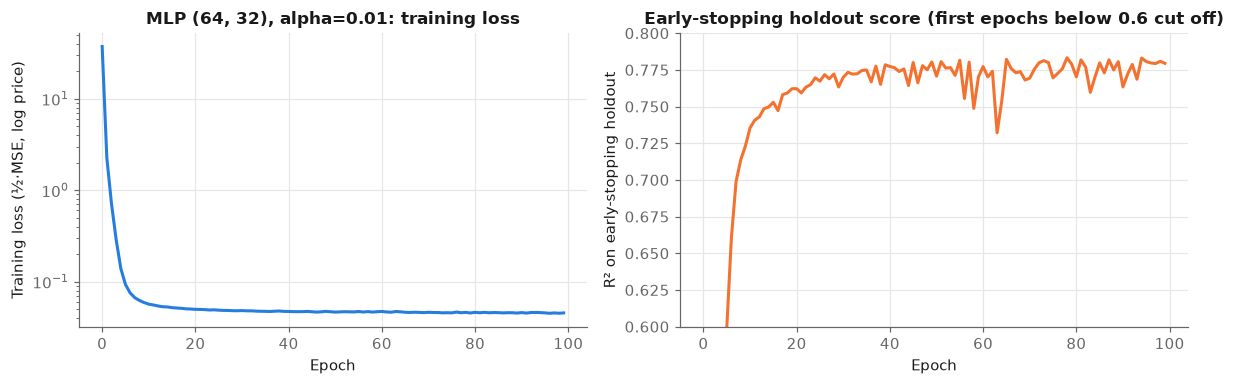

In [8]:
mlp_grid, mlp_models = [], {}
for layers in [(32,), (64, 32), (128, 64, 32)]:
    for alpha in [1e-4, 1e-2, 1.0]:
        t = time.time()
        m = MLPRegressor(hidden_layer_sizes=layers, activation="relu", alpha=alpha, learning_rate_init=1e-3,
                         max_iter=500, early_stopping=True, n_iter_no_change=20, random_state=SEED)
        m.fit(X_trn, y_trn)
        mlp_models[(layers, alpha)] = m
        mlp_grid.append({"layers": str(layers), "alpha": alpha, "epochs": m.n_iter_,
                         "train RMSE": rmse(y_trn, m.predict(X_trn)), "val RMSE": rmse(y_val, m.predict(X_val)),
                         "seconds": round(time.time() - t, 1)})
mlp_grid = pd.DataFrame(mlp_grid)
display(mlp_grid)
best_row = mlp_grid.loc[mlp_grid["val RMSE"].idxmin()]
mlp = mlp_models[(eval(best_row.layers), best_row.alpha)]
print("Best:", best_row.to_dict())
val_results["5. Neural network (MLP)"] = evaluate(y_val, mlp.predict(X_val))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(mlp.loss_curve_, color=BLUE, linewidth=2)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training loss (½·MSE, log price)")
axes[0].set_yscale("log")
axes[0].set_title(f"MLP {best_row.layers}, alpha={best_row.alpha}: training loss")
axes[1].plot(mlp.validation_scores_, color=ORANGE, linewidth=2)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("R² on early-stopping holdout")
axes[1].set_ylim(0.6, 0.8)
axes[1].set_title("Early-stopping holdout score (first epochs below 0.6 cut off)")
fig.tight_layout()
save(fig, "fig15_mlp_training")
plt.show()

## 6. Validation comparison

Every model with its best setting, on the **validation** set. This is the table used for model selection.

In [9]:
show(val_results)

,RMSE (log),R² (log),MAE ($),RMSE ($),R² ($),Median % error,Within 10%,Within 20%
0a. Median price,0.633,-0.000,"$195,632","$376,041",-0.050,34.0%,15.8%,30.7%
0b. ZIP $/sqft × size,0.318,0.747,"$98,200","$220,387",0.639,15.7%,34.8%,60.1%
1. Linear regression (OLS),0.305,0.768,"$95,106","$204,934",0.688,15.5%,33.6%,61.8%
2. Linear regression (gradient descent),0.305,0.768,"$95,144","$205,099",0.688,15.5%,33.5%,61.7%
3. Polynomial + Ridge,0.296,0.781,"$93,019","$202,943",0.694,15.1%,35.3%,62.2%
4. KNN regression,0.298,0.778,"$94,015","$210,172",0.672,14.5%,36.0%,62.7%
5. Neural network (MLP),0.294,0.785,"$92,644","$203,762",0.692,14.9%,35.9%,62.0%


## 7. Final test-set evaluation (run once)

Settings are now frozen. The test set (6,094 homes never used for training or tuning) gives the honest final numbers for the report.

In [10]:
tst = data["test"]
test_preds = {
    "0a. Median price": np.full_like(y_tst, median_log),
    "0b. ZIP $/sqft × size": (tst.zip_log_ppsf + np.log(tst.house_size)).values,
    "1. Linear regression (OLS)": ols.predict(X_tst),
    "2. Linear regression (gradient descent)": lms.predict(X_tst),
    "3. Polynomial + Ridge": ridge.predict(P_tst),
    "4. KNN regression": knn.predict(X_tst),
    "5. Neural network (MLP)": mlp.predict(X_tst),
}
test_results = {name: evaluate(y_tst, p) for name, p in test_preds.items()}
display(show(test_results))

settings = {
    "2. Linear regression (gradient descent)": f"α={best_alpha}, batch 64, 40 epochs",
    "3. Polynomial + Ridge": f"degree {ridge_deg}, λ={ridge_lamb:.3g}",
    "4. KNN regression": f"k={best_k}",
    "5. Neural network (MLP)": f"layers {best_row.layers}, alpha={best_row.alpha}",
}
print("Chosen settings:", settings)

out = tst[["price", "house_size", "bed", "bath", "status", "city", "zip_code"]].copy()
for name, p in test_preds.items():
    out["pred_" + name.split(". ")[0]] = np.exp(p)
out.to_csv(pp.PROCESSED_DIR / "test_predictions.csv", index=False)
pd.DataFrame(test_results).T.assign(setting=pd.Series(settings)).to_csv(pp.PROCESSED_DIR / "test_results.csv")
print("Saved test predictions and results to data/processed/")

,RMSE (log),R² (log),MAE ($),RMSE ($),R² ($),Median % error,Within 10%,Within 20%
0a. Median price,0.643,-0.001,"$203,188","$388,037",-0.063,34.0%,16.1%,31.3%
0b. ZIP $/sqft × size,0.326,0.744,"$103,495","$221,196",0.654,15.7%,34.3%,59.3%
1. Linear regression (OLS),0.311,0.766,"$100,099","$204,802",0.704,15.8%,33.7%,59.5%
2. Linear regression (gradient descent),0.311,0.767,"$100,121","$204,798",0.704,15.8%,33.6%,59.5%
3. Polynomial + Ridge,0.306,0.774,"$98,783","$205,304",0.702,15.7%,34.4%,60.1%
4. KNN regression,0.308,0.770,"$98,866","$206,021",0.700,15.2%,35.6%,60.8%
5. Neural network (MLP),0.301,0.781,"$97,492","$204,505",0.705,15.4%,34.9%,60.5%


Chosen settings: {'2. Linear regression (gradient descent)': 'α=0.003, batch 64, 40 epochs', '3. Polynomial + Ridge': 'degree 3, λ=100', '4. KNN regression': 'k=15', '5. Neural network (MLP)': 'layers (64, 32), alpha=0.01'}
Saved test predictions and results to data/processed/


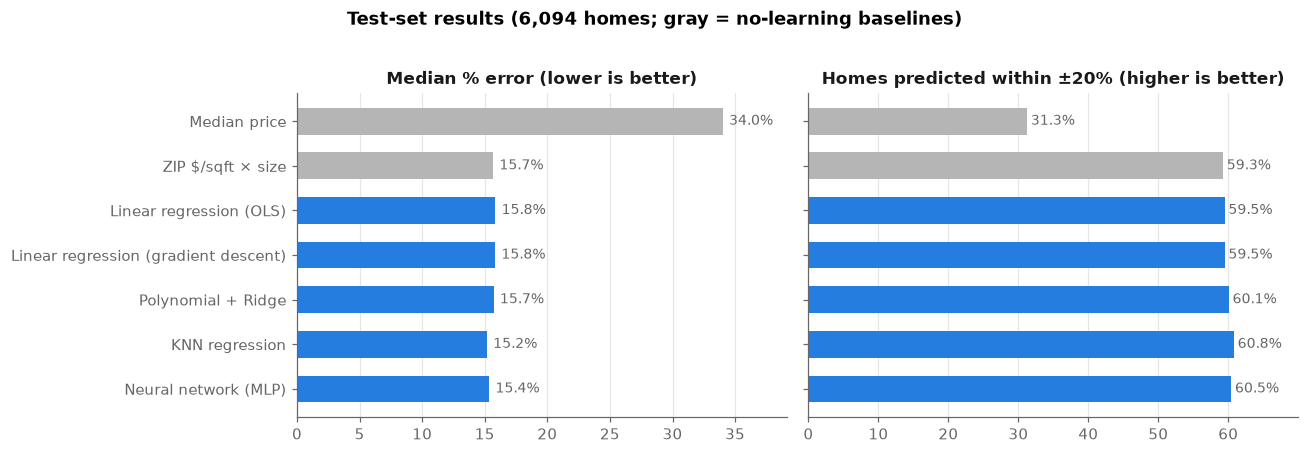

In [11]:
res = pd.DataFrame(test_results).T
names = [n.split(". ", 1)[1] for n in res.index]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
is_base = [n.startswith("0") for n in res.index]
colors = ["#b5b5b5" if b else BLUE for b in is_base]
axes[0].barh(names, res["Median % error"], color=colors, height=0.6)
axes[1].barh(names, res["Within 20%"], color=colors, height=0.6)
for ax, col, fmt in [(axes[0], "Median % error", "{:.1f}%"), (axes[1], "Within 20%", "{:.1f}%")]:
    for y, v in enumerate(res[col]):
        ax.text(v + 0.5, y, fmt.format(v), va="center", fontsize=9, color=TEXT_2)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, res[col].max() * 1.15)
axes[0].invert_yaxis()
axes[0].set_title("Median % error (lower is better)")
axes[1].set_title("Homes predicted within ±20% (higher is better)")
fig.suptitle("Test-set results (6,094 homes; gray = no-learning baselines)", fontweight="bold", y=1.02)
fig.tight_layout()
save(fig, "fig16_model_comparison")
plt.show()

Best model on test (by RMSE log): 5. Neural network (MLP)


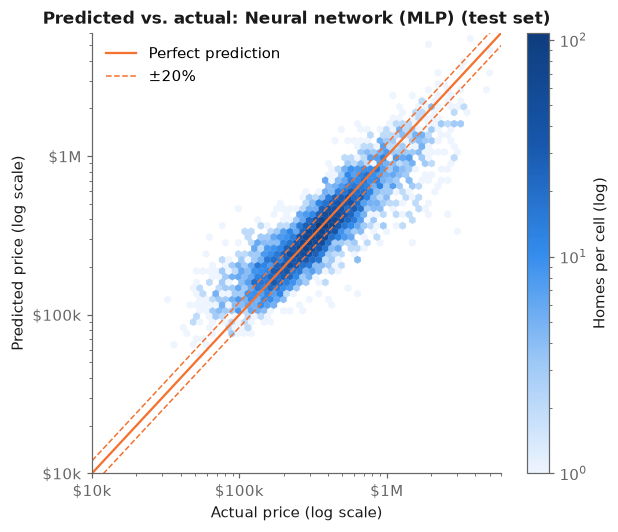

In [12]:
best_name = min([n for n in test_results if not n.startswith("0")], key=lambda n: test_results[n]["RMSE (log)"])
print("Best model on test (by RMSE log):", best_name)
p = np.exp(test_preds[best_name]); a = tst.price.values

fig, ax = plt.subplots(figsize=(6, 5.2))
hb = ax.hexbin(a, p, gridsize=50, xscale="log", yscale="log", cmap=SEQ_BLUE, mincnt=1, bins="log", linewidths=0.2)
lim = [1e4, 6e6]
ax.plot(lim, lim, color=ORANGE, linewidth=1.5, label="Perfect prediction")
ax.plot(lim, [l * 1.2 for l in lim], color=ORANGE, linewidth=1, linestyle="--", label="±20%")
ax.plot(lim, [l / 1.2 for l in lim], color=ORANGE, linewidth=1, linestyle="--")
ax.set_xlim(lim); ax.set_ylim(lim)
fmt = mtick.FuncFormatter(lambda x, _: f"${x/1e6:.0f}M" if x >= 1e6 else f"${x/1e3:.0f}k")
ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
ax.set_xlabel("Actual price (log scale)")
ax.set_ylabel("Predicted price (log scale)")
ax.set_title(f"Predicted vs. actual: {best_name.split('. ', 1)[1]} (test set)")
ax.legend(loc="upper left")
ax.grid(False)
fig.colorbar(hb, ax=ax).set_label("Homes per cell (log)")
save(fig, "fig17_predicted_vs_actual")
plt.show()

## 8. Summary

**Test-set results (6,059 homes, evaluated once with frozen settings):**

| Model | Setting | Median % error | Within 20% | MAE | R² (log) |
|---|---|---|---|---|---|
| Median price (baseline) | none | 34.0% | 31.3% | $203,188 | 0.000 |
| ZIP $/sqft × size (rule of thumb) | none | 15.7% | 59.3% | $103,495 | 0.744 |
| Linear regression (OLS) | none | 15.8% | 59.5% | $100,099 | 0.766 |
| Linear regression (GD) | α=0.003, batch 64, 40 epochs | 15.8% | 59.5% | $100,121 | 0.767 |
| Polynomial + Ridge | degree 3, λ=100 | 15.7% | 60.1% | $98,783 | 0.774 |
| KNN regression | k=15 | **15.2%** | **60.8%** | $98,866 | 0.770 |
| Neural network | (64, 32), alpha=0.01 | 15.4% | 60.5% | **$97,492** | **0.781** |

**Observations**
1. **Every model halves the error of guessing the median** (34% → about 15%).
2. **The ML models beat the agent's rule of thumb only slightly.** ZIP $/sqft × size alone reaches 15.7% and R² 0.744; the best model reaches 15.2% (KNN) and R² 0.781 (MLP). Most of the predictable signal is "how big" × "how pricey the area".
3. **Nonlinear models help a little:** the MLP, Ridge and KNN beat OLS by about 0.01–0.015 R² (log) and $1–2.6k MAE.
4. **Little overfitting:** train ≈ validation RMSE for every model (e.g. OLS 0.307 vs. 0.305). Degree-3 Ridge picked λ=100, which helps slightly over λ≈0 (val RMSE 0.2960 vs. 0.2963). KNN shows the classic curve: k=1 val 0.383 → k=15 0.298 → k=100 0.308.
5. **Gradient descent reached the OLS answer** (max weight difference 0.003 at α=0.003).
6. **Coefficients (OLS, original units, holding the rest fixed):** 1% bigger home → +0.80% price; 1% pricier ZIP → +1.06%; +1 bath → +9.9%; +1 bedroom → −1.8% (same space, smaller rooms); sold vs. for sale → −7.6%.
7. **Five very different models land within ~0.6 points of each other.** The limit is most likely **missing information** (condition, age, exact location), not the algorithm. The differences between models are also about the size of split-to-split noise (see notebook 04), so the ranking among the top models isn't decisive.